In [1]:
import pandas as pd
import numpy as np
import pickle
from utils import *

/home/jperera/fuzhom/fuzhom_venv/lib/python3.10/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [2]:
with open('files/datasets.pkl', 'rb') as f:
    datasets = pickle.load(f)

In [3]:
medians_df = pd.DataFrame({
    'Dataset type': [d['title'] for d in datasets],
    'Q1 F1-score': [np.percentile(d['f1'], 25) for d in datasets],
    'Median F1-score': [np.median(d['f1']) for d in datasets],
    'Q3 F1-score': [np.percentile(d['f1'], 75) for d in datasets]
})
pd.set_option('display.max_rows', None)
medians_df

,Dataset type,Q1 F1-score,Median F1-score,Q3 F1-score
0,Non-top.,0.843478,0.856719,0.871206
1,"Alpha, M vs T, dim. 0, L-fuzzy",0.829377,0.843478,0.856719
2,"Alpha, M vs T, dim. 1, L-fuzzy",0.796246,0.818886,0.834038
3,"Alpha, M vs T, Euler char., L-fuzzy",0.829676,0.846969,0.863274
4,"Alpha, M vs T, dim. 0, crisp",0.756502,0.773450,0.797463
5,"Alpha, M vs T, dim. 1, crisp",0.718528,0.737651,0.761053
6,"Alpha, M vs T, Euler char., crisp",0.775849,0.794144,0.818497
7,"Alpha, T vs V, dim. 0, L-fuzzy",0.818601,0.835629,0.847376
8,"Alpha, T vs V, dim. 1, L-fuzzy",0.774334,0.791900,0.808747
9,"Alpha, T vs V, Euler char., L-fuzzy",0.819392,0.840420,0.855072


In [4]:
medians_df.to_latex(
    buf="files/medians.tex",
    longtable=True,
    index=False,
    escape=False,
    caption="Median values",
    label="tab:medians"
)

We ask ourselves:
* What is best: crisp or L-fuzzy?
* What is best: Alpha complex or Chromatic Alpha complex?
* What is best: topological or non topological information?

We will compare the distribution of F1 scores using the Wilcoxon-Mann-Whitney U-test.

In [5]:
alpha = 0.05

### L-fuzzy vs Crisp

In [6]:
fuzzy_df = pd.DataFrame(columns=['Dataset type', 'Median L-fuzzy', 'Median Crisp','Winner'])
for i in [1,2,3,7,8,9,13,14,15,19,20,21,25,26,27,31,32,33]:
    r1, r2 = i, i+3
    d1, d2 = datasets[r1], datasets[r2]
    options = ['Tie','L-fuzzy','Crisp']
    winner = options[compare_samples(d1['f1'],d2['f1'],alpha)]
    fuzzy_df.loc[len(fuzzy_df)] = [d1['title'].replace(', L-fuzzy', ''), np.median(d1['f1']), np.median(d2['f1']), winner]
fuzzy_df

,Dataset type,Median L-fuzzy,Median Crisp,Winner
0,"Alpha, M vs T, dim. 0",0.843478,0.773450,L-fuzzy
1,"Alpha, M vs T, dim. 1",0.818886,0.737651,L-fuzzy
2,"Alpha, M vs T, Euler char.",0.846969,0.794144,L-fuzzy
3,"Alpha, T vs V, dim. 0",0.835629,0.795792,L-fuzzy
4,"Alpha, T vs V, dim. 1",0.791900,0.778881,L-fuzzy
5,"Alpha, T vs V, Euler char.",0.840420,0.785456,L-fuzzy
6,"Alpha, M vs V, dim. 0",0.818330,0.785507,L-fuzzy
7,"Alpha, M vs V, dim. 1",0.736722,0.744444,Tie
8,"Alpha, M vs V, Euler char.",0.816118,0.789837,L-fuzzy
9,"Chr. Alpha, M vs T, dim. 0",0.842552,0.773748,L-fuzzy


In [7]:
fuzzy_df['Winner'].value_counts()

Winner
L-fuzzy    16
Tie         1
Crisp       1
Name: count, dtype: int64

In general, using the L-fuzzy Betti curves provides more information and trains better Random Forests than just the crisp Betti curves. There is only one situation in which the crisp curve is better.

### Alpha Complex vs Chromatic Alpha Complex

In [8]:
alpha_df = pd.DataFrame(columns=['Dataset type', 'Median Alpha', 'Median Chr. Alpha', 'Winner'])
for i in [1,2,3,7,8,9,13,14,15]:
    r1, r2 = i, i + 18
    d1, d2 = datasets[r1], datasets[r2]
    options = ['Tie', 'Alpha', 'Chr. Alpha']
    winner = options[compare_samples(d1['f1'], d2['f1'], alpha)]
    alpha_df.loc[len(alpha_df)] = [
        d1['title'].split(',', 1)[1].strip(), np.median(d1['f1']), np.median(d2['f1']), winner]
alpha_df

,Dataset type,Median Alpha,Median Chr. Alpha,Winner
0,"M vs T, dim. 0, L-fuzzy",0.843478,0.842552,Tie
1,"M vs T, dim. 1, L-fuzzy",0.818886,0.814572,Tie
2,"M vs T, Euler char., L-fuzzy",0.846969,0.849158,Tie
3,"T vs V, dim. 0, L-fuzzy",0.835629,0.832277,Tie
4,"T vs V, dim. 1, L-fuzzy",0.791900,0.787316,Tie
5,"T vs V, Euler char., L-fuzzy",0.840420,0.838240,Tie
6,"M vs V, dim. 0, L-fuzzy",0.818330,0.816033,Tie
7,"M vs V, dim. 1, L-fuzzy",0.736722,0.728154,Alpha
8,"M vs V, Euler char., L-fuzzy",0.816118,0.818163,Tie


In [9]:
alpha_df['Winner'].value_counts()

Winner
Tie      8
Alpha    1
Name: count, dtype: int64

In general, using the Chromatic Alpha filtration to compute the L-fuzzy Betti curve is never significantly better than using the Alpha filtration. Moreover, using the Alpha filtration is faster (25 minutes against 2 hours), so we will prefer the L-fuzzy Betti curves coming from Alpha filtrations.

### Alpha L-fuzzy vs Six-pack

In [10]:
asix_df = pd.DataFrame(columns=['Dataset type', 'Median L-fuzzy', 'Median Six-pack','Winner'])
for r1, r2 in zip([1,2,3,7,8,9,13,14,15],range(37,46)):
    d1, d2 = datasets[r1], datasets[r2]
    options = ['Tie','Alpha','Six-pack']
    winner = options[compare_samples(d1['f1'],d2['f1'],alpha)]
    asix_df.loc[len(asix_df)] = [d1['title'].replace('Alpha, ','').replace(', L-fuzzy',''), np.median(d1['f1']), np.median(d2['f1']), winner]
asix_df

,Dataset type,Median L-fuzzy,Median Six-pack,Winner
0,"M vs T, dim. 0",0.843478,0.833327,Alpha
1,"M vs T, dim. 1",0.818886,0.802826,Alpha
2,"M vs T, Euler char.",0.846969,0.834770,Alpha
3,"T vs V, dim. 0",0.835629,0.835629,Tie
4,"T vs V, dim. 1",0.791900,0.845915,Six-pack
5,"T vs V, Euler char.",0.840420,0.842818,Tie
6,"M vs V, dim. 0",0.818330,0.815948,Tie
7,"M vs V, dim. 1",0.736722,0.790841,Six-pack
8,"M vs V, Euler char.",0.816118,0.826373,Six-pack


In [11]:
asix_df['Winner'].value_counts()

Winner
Alpha       3
Tie         3
Six-pack    3
Name: count, dtype: int64

Here we cannot find a pattern. Depending on the chosen options, either the L-fuzzy Betti curves from Alpha filtrations or the Betti curves from the Six-pack can train better or worse models. Again, computing the L-fuzzy Betti curves from Alpha filtrations is significantly faster (25 minutes against 1h 25 minutes).

### Non-top. vs Topological

In [12]:
nontop_df = pd.DataFrame(columns=['Topological', 'Median Non-top.', 'Median Topological ','Winner'])
for i in range(1,46):
    r1, r2 = 0, i
    d1, d2 = datasets[r1], datasets[r2]
    options = ['Tie','Non topological','Topological']
    winner = options[compare_samples(d1['f1'],d2['f1'],alpha)]
    nontop_df.loc[len(nontop_df)] = [d2['title'], np.median(d1['f1']), np.median(d2['f1']), winner]
nontop_df

,Topological,Median Non-top.,Median Topological,Winner
0,"Alpha, M vs T, dim. 0, L-fuzzy",0.856719,0.843478,Non topological
1,"Alpha, M vs T, dim. 1, L-fuzzy",0.856719,0.818886,Non topological
2,"Alpha, M vs T, Euler char., L-fuzzy",0.856719,0.846969,Non topological
3,"Alpha, M vs T, dim. 0, crisp",0.856719,0.773450,Non topological
4,"Alpha, M vs T, dim. 1, crisp",0.856719,0.737651,Non topological
5,"Alpha, M vs T, Euler char., crisp",0.856719,0.794144,Non topological
6,"Alpha, T vs V, dim. 0, L-fuzzy",0.856719,0.835629,Non topological
7,"Alpha, T vs V, dim. 1, L-fuzzy",0.856719,0.791900,Non topological
8,"Alpha, T vs V, Euler char., L-fuzzy",0.856719,0.840420,Non topological
9,"Alpha, T vs V, dim. 0, crisp",0.856719,0.795792,Non topological


In [13]:
nontop_df['Winner'].value_counts()

Winner
Non topological    45
Name: count, dtype: int64

The non topological information, which is much more simple, always trains better models.

### Non topological vs Combined information

In [14]:
combined_df = pd.DataFrame(columns=['Combined', 'Median Non-top.', 'Median Combined ','Winner'])
for i in range(46,91):
    r1, r2 = 0, i
    d1, d2 = datasets[r1], datasets[r2]
    options = ['Tie','Non topological','Combined']
    winner = options[compare_samples(d1['f1'],d2['f1'],alpha)]
    combined_df.loc[len(combined_df)] = [d2['title'], np.median(d1['f1']), np.median(d2['f1']), winner]
combined_df

,Combined,Median Non-top.,Median Combined,Winner
0,"Non-top. + Alpha, M vs T, dim. 0, L-fuzzy",0.856719,0.864706,Combined
1,"Non-top. + Alpha, M vs T, dim. 1, L-fuzzy",0.856719,0.841626,Non topological
2,"Non-top. + Alpha, M vs T, Euler char., L-fuzzy",0.856719,0.860668,Tie
3,"Non-top. + Alpha, M vs T, dim. 0, crisp",0.856719,0.861668,Tie
4,"Non-top. + Alpha, M vs T, dim. 1, crisp",0.856719,0.842427,Non topological
5,"Non-top. + Alpha, M vs T, Euler char., crisp",0.856719,0.855896,Tie
6,"Non-top. + Alpha, T vs V, dim. 0, L-fuzzy",0.856719,0.848393,Non topological
7,"Non-top. + Alpha, T vs V, dim. 1, L-fuzzy",0.856719,0.833749,Non topological
8,"Non-top. + Alpha, T vs V, Euler char., L-fuzzy",0.856719,0.846572,Non topological
9,"Non-top. + Alpha, T vs V, dim. 0, crisp",0.856719,0.840058,Non topological


In [15]:
combined_df['Winner'].value_counts()

Winner
Non topological    30
Tie                13
Combined            2
Name: count, dtype: int64

In [16]:
combined_df.loc[combined_df['Winner'] == 'Combined', 'Combined']

0          Non-top. + Alpha, M vs T, dim. 0, L-fuzzy
18    Non-top. + Chr. Alpha, M vs T, dim. 0, L-fuzzy
Name: Combined, dtype: object

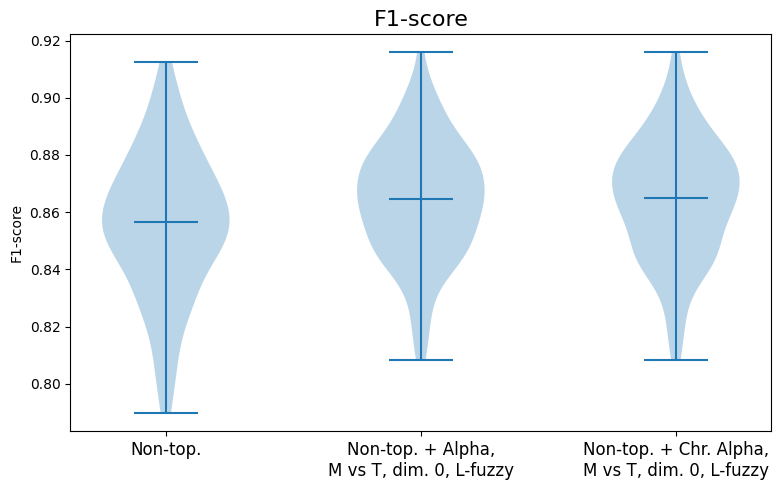

In [17]:
import textwrap

r1, r2, r3 = 0, 46, 64
d1, d2, d3 = datasets[r1], datasets[r2], datasets[r3]
sample1, sample2, sample3 = d1['f1'], d2['f1'], d3['f1']

max_width = 23
wrapped_labels = [
    d['title'].replace('Alpha, ', 'Alpha,\n') for d in (d1, d2, d3)
]

plt.figure(figsize=(8, 5))
plt.title("F1-score", fontsize=16)

plt.violinplot([sample1, sample2, sample3], showmedians=True)

plt.xticks(
    [1, 2, 3], 
    wrapped_labels, 
    rotation=0, 
    ha='center', 
    fontsize=12
)

plt.ylabel('F1-score')
plt.tight_layout()
plt.savefig('plots/f1scores.pdf', bbox_inches='tight')
plt.show()